# MNIST VAE training


In [1]:
import torch
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

from hsp.plotting import LossPlotter
from hsp.vae import VAE

torch.manual_seed(0)

## Load MNIST


In [2]:
mnist_train = MNIST(root="data", train=True, download=True, transform=ToTensor())
data_loader = DataLoader(mnist_train, batch_size=64, shuffle=True)

images, labels = next(iter(data_loader))
data = images.flatten(start_dim=1)
print(data.shape)  # torch.Size([64, 784])

torch.Size([64, 784])


## Create the VAE


In [3]:
vae = VAE(input_dim=784, latent_dim=2, hidden_dim=128)
optimizer = torch.optim.Adam(vae.parameters(), lr=0.001)

## Train

For every mini-batch, flatten the images, run the VAE, calculate its loss, and update the weights. The numeric loss from each training step is stored for the plot.

In [4]:
losses = []
vae.train()

for epoch in range(3):
    for images, _ in data_loader:
        data = images.flatten(start_dim=1)
        reconstruction, mu, logvar = vae.forward(data)
        loss = vae.loss(reconstruction, data, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    print(f"epoch {epoch}: loss = {loss.item():.4f}")

epoch 0: loss = 0.0662
epoch 1: loss = 0.0659
epoch 2: loss = 0.0679


## Plot the loss

The notebook delegates plotting to the library class instead of constructing a Matplotlib graph itself.

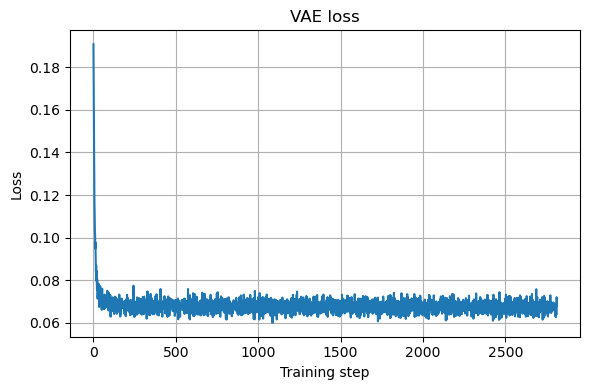

In [5]:
LossPlotter().plot({"VAE": losses})[0]